In [1]:
import os
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from torchvision import transforms
from exercise_code.networks.keypoint_nn import (
    DummyKeypointModel,
    KeypointModel
)
from exercise_code.util import (
    show_all_keypoints,
    save_model,
)
import torch.nn as nn
from exercise_code.tests import test_keypoint_nn

import torch 
import torch.nn as nn
import torchvision 
import torchvision.transforms as transforms

import matplotlib.pyplot as plt

import torch.backends
import torch.backends.mps

import torch.utils
import torch.utils.data

from torch.optim.lr_scheduler import StepLR, LambdaLR
from torch.utils.tensorboard import SummaryWriter
import copy
import random
import os
import torchvision.transforms.functional as TF
from exercise_code.data.base_dataset import BaseDataset
import torchvision.transforms.functional as F
import math
import numpy as np
import pandas as pd
 

In [2]:
class TranslateTransform:
    def __call__(self, image, target):
        p = random.random()
        if p > 0.5:            
            x = random.randint(-20, 20)
            y = random.randint(-20, 20)
            image = F.affine(image, angle=0, translate=[x, y], scale=1, shear=0)

            target[:, 0] += x / 48
            target[:, 1] += y / 48

        return image, target
    

class RotateTransform:
    def __call__(self, image, target): 
        # rotation
        p = random.random()
        if p > 0.5: 
            angle = random.randint(-30, 30)
            image = F.rotate(image, angle)

            angle = torch.tensor(angle).float()

            # rotate keypoints
            angle = angle * 3.14159 / 180
            rot_matrix = torch.tensor([[torch.cos(angle), -torch.sin(angle)], [torch.sin(angle), torch.cos(angle)]])
            target = torch.mm(target, rot_matrix)

        return image, target
    
class BlurTransform:
    def __call__(self, image, target): 
        # add gaussian blur 
        p = random.random()
        if p > 0.5: 
            image = F.gaussian_blur(image, kernel_size=5)

        return image, target
    
class FlipTransform:
    def __call__(self, image, target): 
        # horizontal flip
        p = random.random()
        if p > 0.5: 
            image = F.hflip(image)
            target[:, 0] *= -1

        return image, target
    
class MissingPixelsTransform:
    def __call__(self, image, target): 
        # add random missing pixels
        p = random.random()
        if p > 0.5: 
            mask = torch.rand(size = image.shape) 
            mask[mask <= 0.05] = 0  
            mask[mask > 0.05] = 1
            image = mask * image 

        return image, target
    

class FacialKeypointsDataset(BaseDataset):
    """Dataset for facial keypoint detection"""
    def __init__(self, *args, train=True, **kwargs):
        super().__init__(*args, **kwargs)
        self.train = train
        file_name = "training.csv" if train else "val.csv"
        csv_file = os.path.join(self.root_path, file_name)
        self.key_pts_frame = pd.read_csv(csv_file)
        self.key_pts_frame.dropna(inplace=True)
        self.key_pts_frame.reset_index(drop=True, inplace=True)

        # init transforms 
        self.translate_transform = TranslateTransform()
        self.rotate_transform = RotateTransform()
        self.blur_transform = BlurTransform()
        self.flip_transform = FlipTransform()
        self.missing_pixels_transform = MissingPixelsTransform()

    @staticmethod
    def _get_image(idx, key_pts_frame):
        img_str = key_pts_frame.loc[idx]['Image']
        img = np.array([
            int(item) for item in img_str.split()
        ]).reshape((96, 96))
        return np.expand_dims(img, axis=2).astype(np.uint8)

    @staticmethod
    def _get_keypoints(idx, key_pts_frame, shape=(15, 2)):
        keypoint_cols = list(key_pts_frame.columns)[:-1]
        key_pts = key_pts_frame.iloc[idx][keypoint_cols].values.reshape(shape)
        key_pts = (key_pts.astype(np.float32) - 48.0) / 48.0
        return torch.from_numpy(key_pts).float()
    
    def _transform(self, image, target): 
        image = F.to_tensor(image)

        # clean validation
        if not self.train: 
            return image, target
        
        # apply random transformations
        # image, target = self.translate_transform(image, target)
        # image, target = self.rotate_transform(image, target)
        # image, target = self.blur_transform(image, target)
        # image, target = self.missing_pixels_transform(image, target)
        # image, target = self.flip_transform(image, target)

        return image, target

    def __len__(self):
        return self.key_pts_frame.shape[0]

    def __getitem__(self, idx):
        image = self._get_image(idx, self.key_pts_frame)
        keypoints = self._get_keypoints(idx, self.key_pts_frame)

        image, keypoints = self._transform(image, keypoints)

        return {'image': image, 'keypoints': keypoints}

In [3]:
download_url = "https://vision.in.tum.de/webshare/g/i2dl/facial_keypoints.zip"
i2dl_exercises_path = os.path.dirname(os.path.abspath(os.getcwd()))
data_root = os.path.join(i2dl_exercises_path, "datasets", "facial_keypoints")
train_dataset = FacialKeypointsDataset(
    train=True,
    root=data_root,
    download_url=download_url,
)
val_dataset = FacialKeypointsDataset(
    train=False,
    root=data_root,
)

print("Number of training samples:", len(train_dataset))
print("Number of validation samples:", len(val_dataset))

Number of training samples: 1546
Number of validation samples: 298


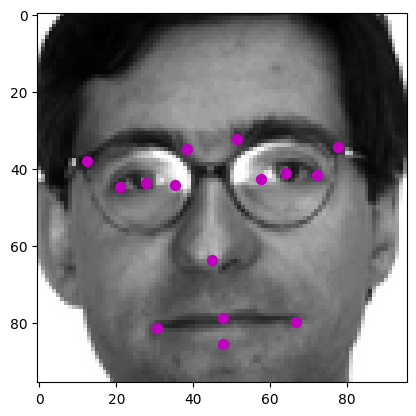

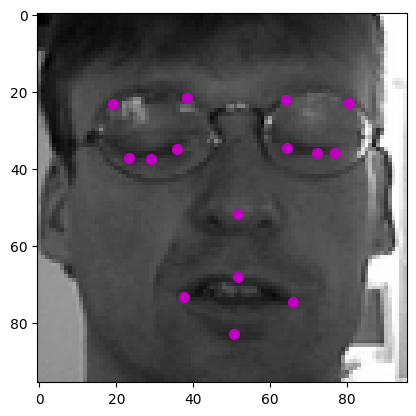

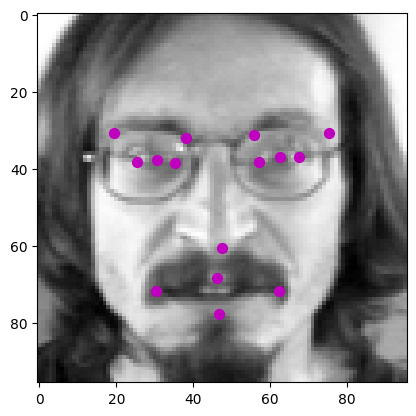

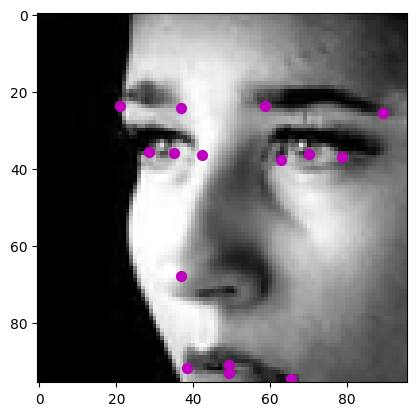

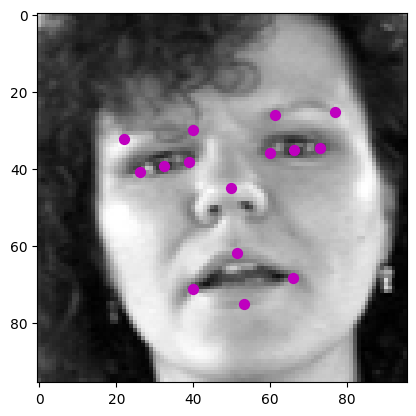

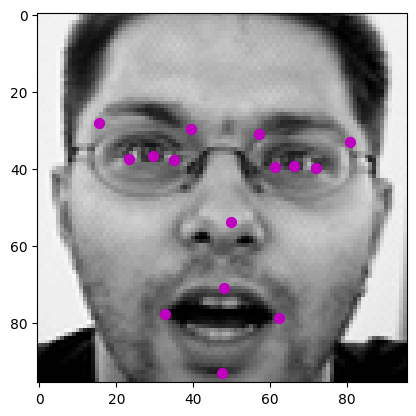

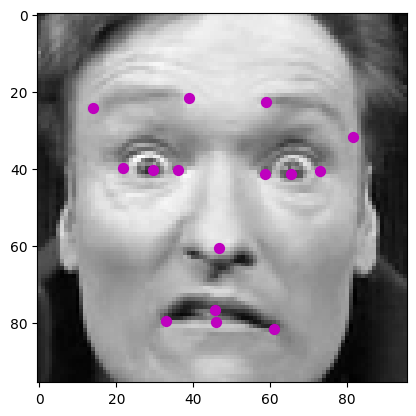

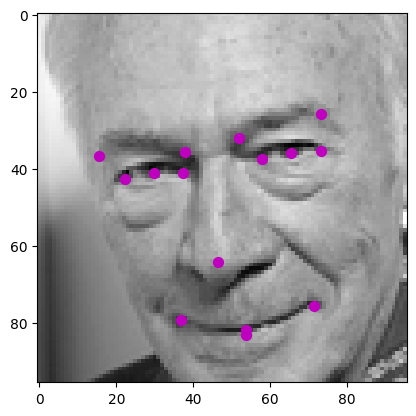

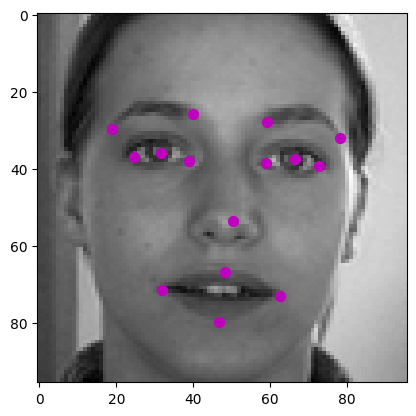

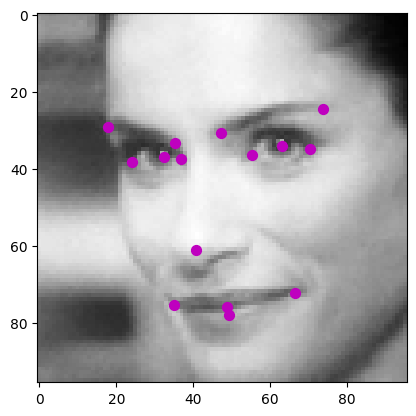

In [4]:
# check train pipeline
def show_keypoints(dataset, num_samples=10):
    for i in range(num_samples):
        idx = random.randint(0, len(dataset))
        data = dataset[idx]
        image, key_pts = data["image"], data["keypoints"]

        show_all_keypoints(image, key_pts)
 

show_keypoints(train_dataset)

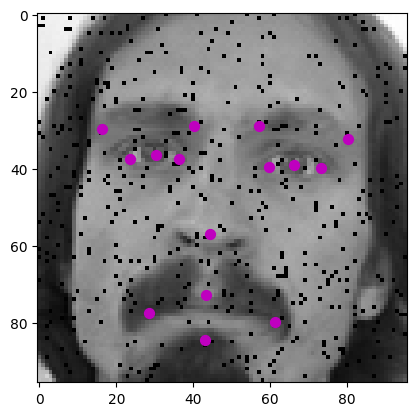

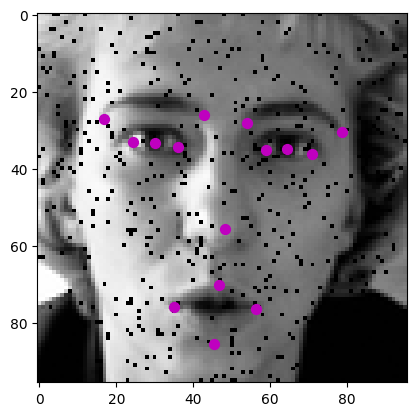

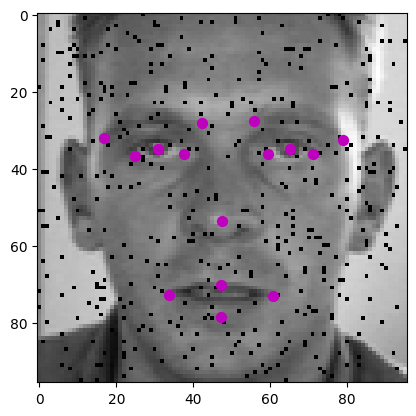

In [5]:
# add missing pixel noise
def show_keypoints(dataset, num_samples=3):
    for i in range(num_samples):
        image = dataset[i]["image"]
        key_pts = dataset[i]["keypoints"]

        # remove pixels
        mask = torch.rand(size = image.shape) 
        mask[mask <= 0.05] = 0  
        mask[mask > 0.05] = 1
        image = mask * image 

        show_all_keypoints(image, key_pts)
 

show_keypoints(val_dataset)

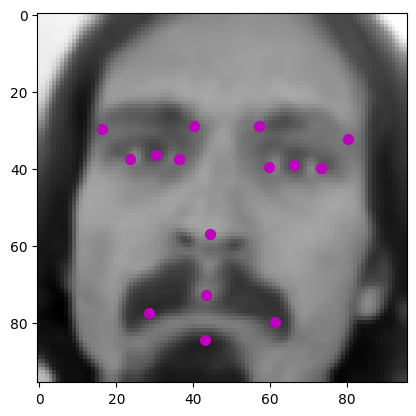

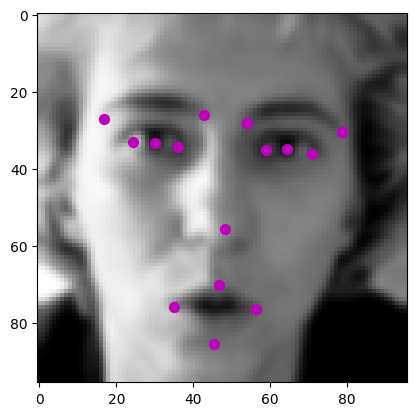

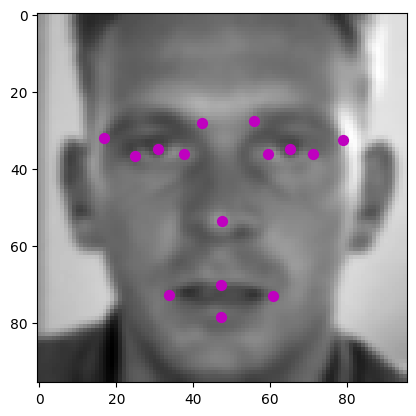

In [6]:
# add gaussian blur 
def show_keypoints(dataset, num_samples=3):
    for i in range(num_samples):
        image = dataset[i]["image"]
        key_pts = dataset[i]["keypoints"]

        image = TF.gaussian_blur(image, kernel_size=5)

        show_all_keypoints(image, key_pts)
 

show_keypoints(val_dataset)

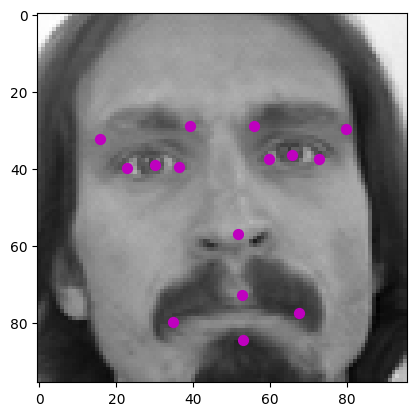

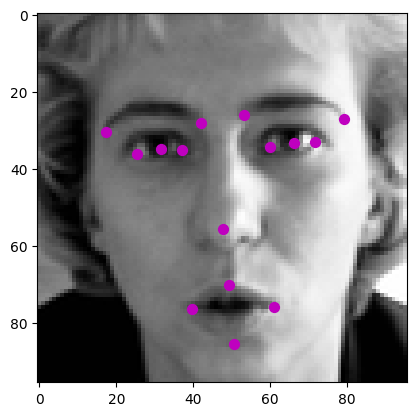

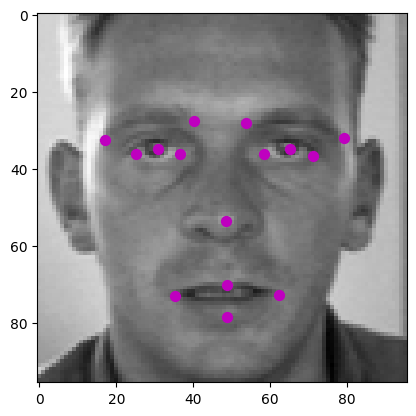

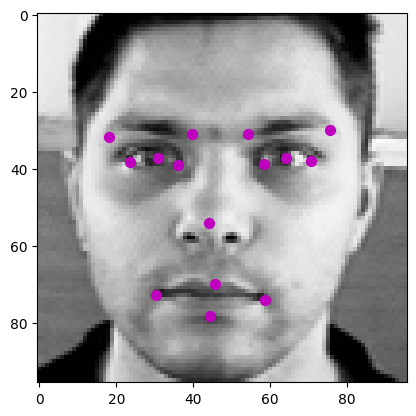

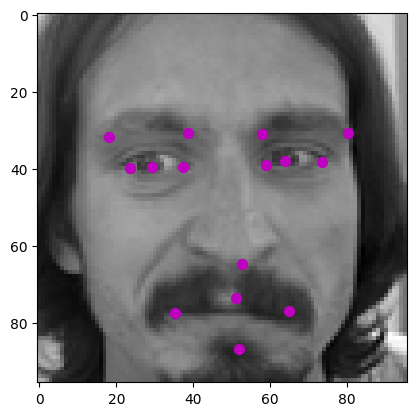

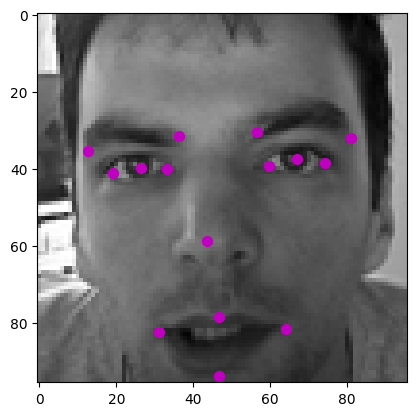

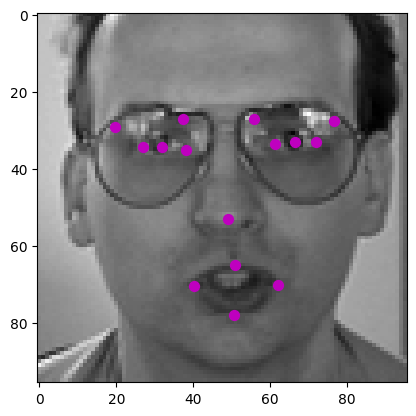

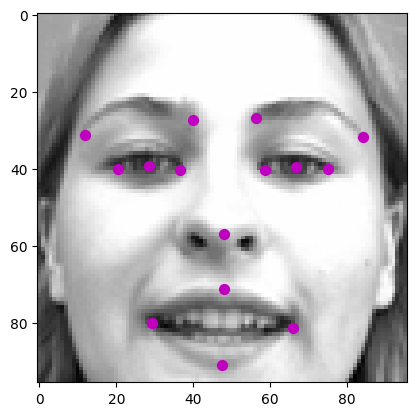

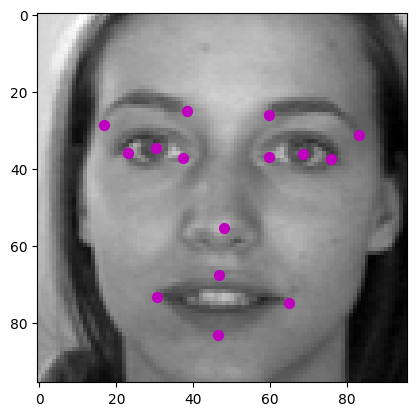

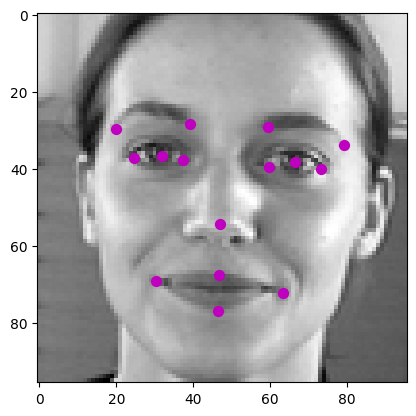

In [7]:
# horizontal flip
def show_keypoints(dataset, num_samples=10):
    for i in range(num_samples):
        image = dataset[i]["image"]
        targets = dataset[i]["keypoints"]

        image = TF.hflip(image)
        targets[:, 0] *= -1

        show_all_keypoints(image, targets)
 

show_keypoints(val_dataset)

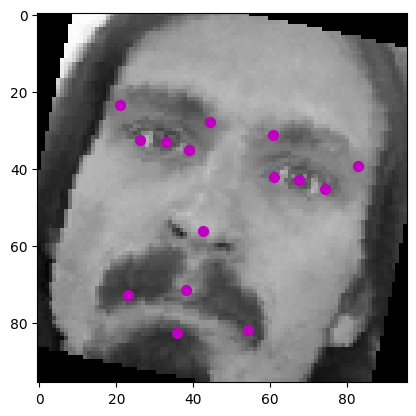

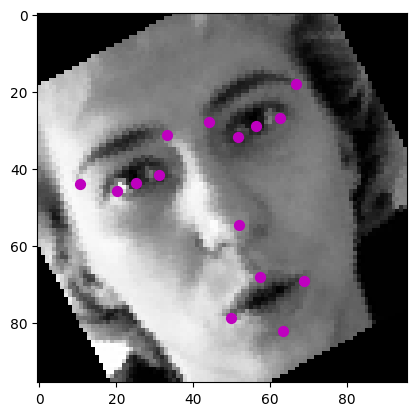

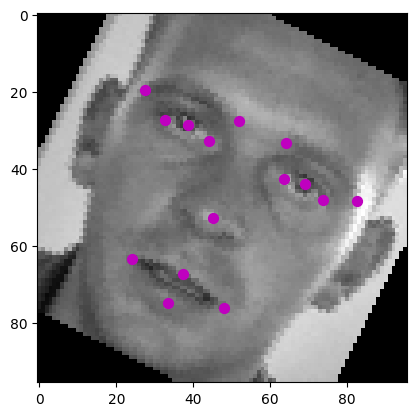

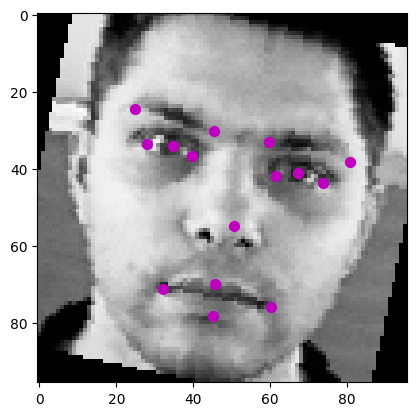

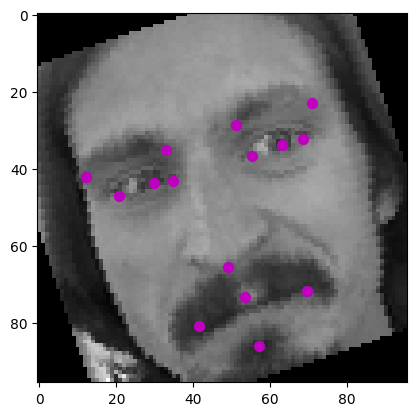

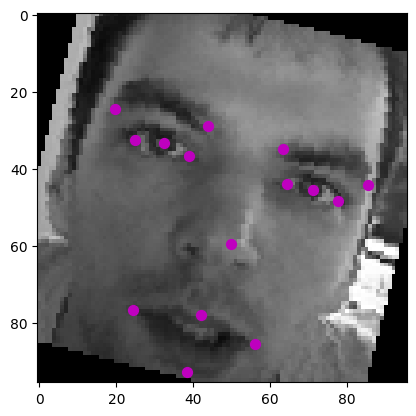

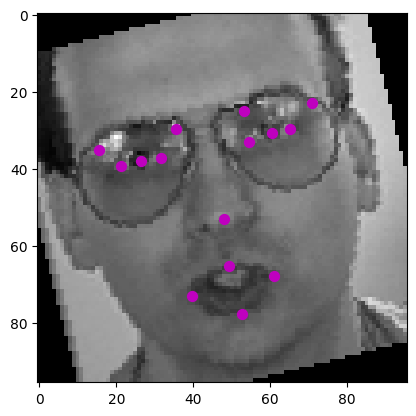

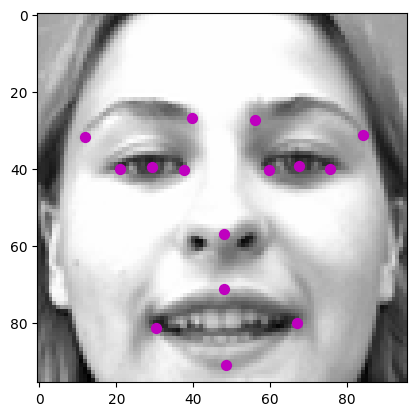

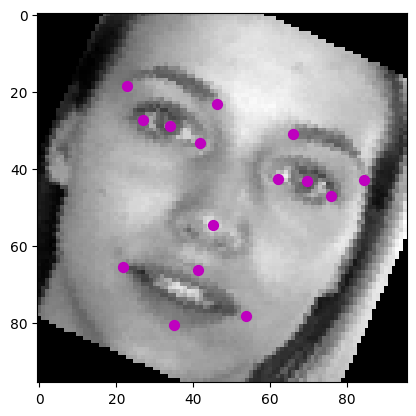

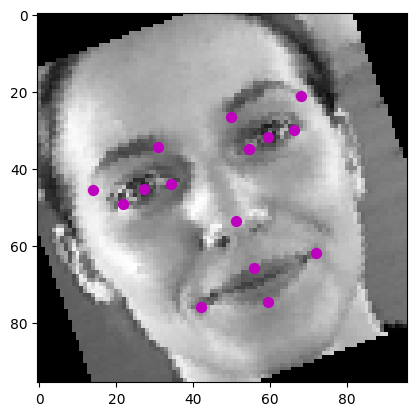

In [8]:
# rotation
def show_keypoints(dataset, num_samples=10):
    for i in range(num_samples):
        image = dataset[i]["image"]
        targets = dataset[i]["keypoints"]

        angle = random.randint(-30, 30)
        image = TF.rotate(image, angle)

        angle = torch.tensor(angle).float()

        # rotate keypoints
        angle = angle * 3.14159 / 180
        rot_matrix = torch.tensor([[torch.cos(angle), -torch.sin(angle)], [torch.sin(angle), torch.cos(angle)]])
        targets = torch.mm(targets, rot_matrix)

        show_all_keypoints(image, targets)
 

show_keypoints(val_dataset)

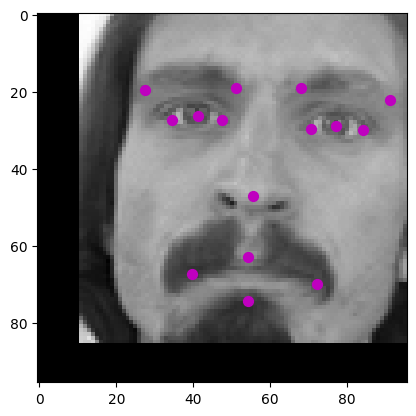

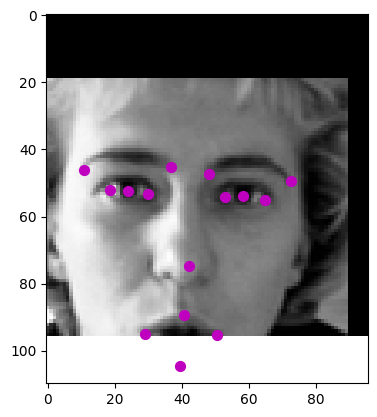

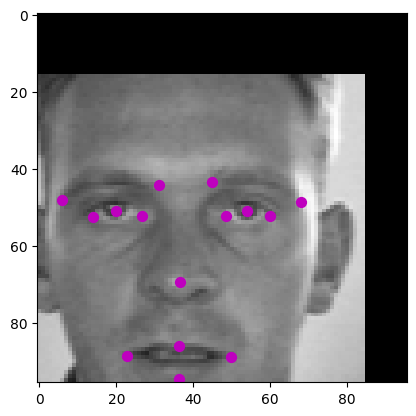

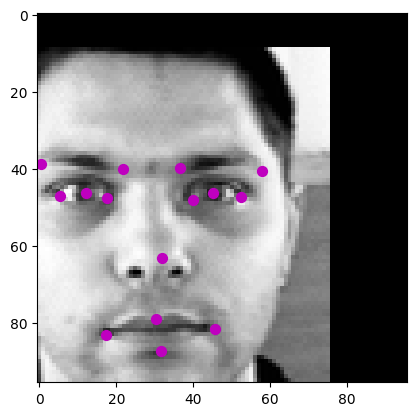

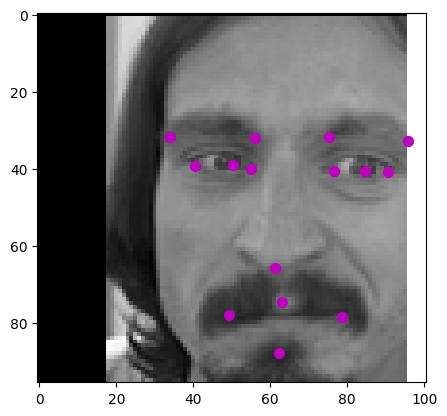

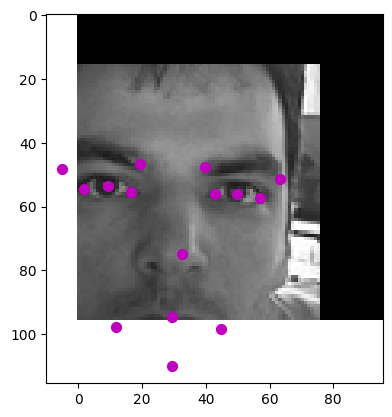

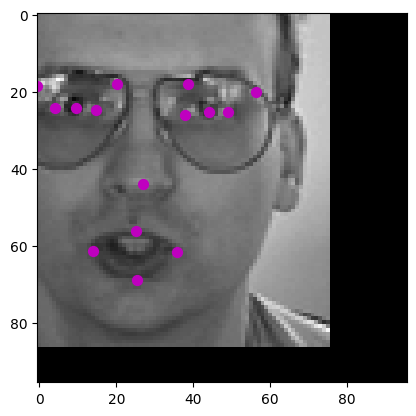

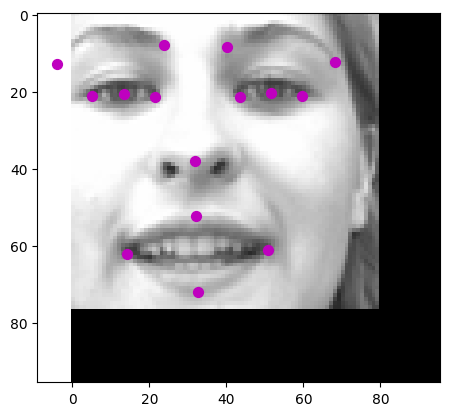

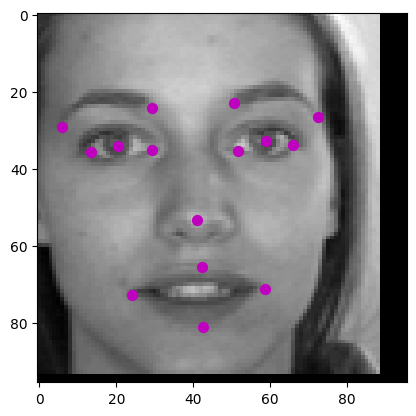

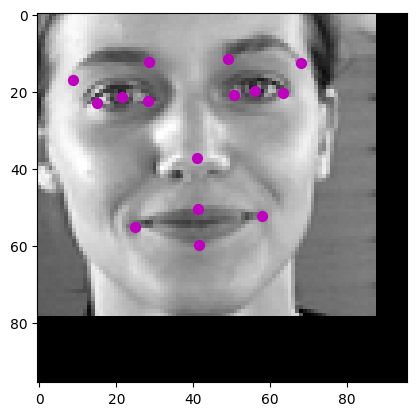

In [9]:
# translation
def show_keypoints(dataset, num_samples=10):
    for i in range(num_samples):
        image = dataset[i]["image"]
        targets = dataset[i]["keypoints"]

        x = random.randint(-20, 20)
        y = random.randint(-20, 20)
        image = TF.affine(image, angle=0, translate=[x, y], scale=1, shear=0)

        targets[:, 0] += x / 48
        targets[:, 1] += y / 48

        show_all_keypoints(image, targets)
 

show_keypoints(val_dataset)

In [10]:
device = "cuda"

In [11]:
dataloader = DataLoader(train_dataset, batch_size=10, shuffle=False)
for batch in dataloader:
    image, keypoints = batch["image"], batch["keypoints"]


    print("Image batch size:", image.shape)
    print("Keypoints batch shape:", keypoints.shape)

    break

image = image[0]
keypoints = keypoints[0]

print("Image shape:", image.shape)
print("Keypoints shape:", keypoints.shape)

Image batch size: torch.Size([10, 1, 96, 96])
Keypoints batch shape: torch.Size([10, 15, 2])
Image shape: torch.Size([1, 96, 96])
Keypoints shape: torch.Size([15, 2])


In [12]:
image

tensor([[[0.3804, 0.2039, 0.2275,  ..., 0.9922, 0.9961, 0.9961],
         [0.3333, 0.2157, 0.2588,  ..., 0.9922, 0.9961, 0.9961],
         [0.2941, 0.2588, 0.2902,  ..., 0.9922, 0.9961, 0.9961],
         ...,
         [0.1294, 0.1255, 0.1255,  ..., 0.9255, 1.0000, 1.0000],
         [0.1294, 0.1255, 0.1216,  ..., 0.9490, 0.9843, 0.9804],
         [0.1216, 0.1176, 0.1216,  ..., 0.9255, 1.0000, 0.9922]]])

In [13]:
keypoints

tensor([[ 0.4685, -0.2319],
        [-0.4253, -0.1953],
        [ 0.2908, -0.2214],
        [ 0.5992, -0.2214],
        [-0.2685, -0.2109],
        [-0.5873, -0.1900],
        [ 0.1967, -0.3827],
        [ 0.7656, -0.4295],
        [-0.2035, -0.3758],
        [-0.7389, -0.3573],
        [ 0.0086,  0.2333],
        [ 0.4163,  0.6620],
        [-0.3521,  0.6985],
        [ 0.0138,  0.6045],
        [ 0.0190,  0.9076]])

In [14]:
class NamishNet(nn.Module): 
    def __init__(self):
        super(NamishNet, self).__init__()

        # input: single channel, 96 x 96
        # 32 filters, 5x5 kernel size, in: 1 channel (grayscale), out: 32 channels, out: 92 x 92
        self.conv1 = nn.Conv2d(1, 32, 5)

        # activation function 
        self.elu1 = nn.ELU()

        # max pooling, 2x2 kernel size, out: 46 x 46
        self.pool1 = nn.MaxPool2d(2, 2)

        # dropout 
        self.dropout1 = nn.Dropout(0.1)

        # 64 filters, 3x3 kernel size, in: 32 channels, out: 64 channels, out: 44 x 44
        # reducing the convolution size to 3x3
        self.conv2 = nn.Conv2d(32, 64, 3)

        # activation function
        self.elu2 = nn.ELU()

        # max pooling, 2x2 kernel size, out: 22 x 22
        self.pool2 = nn.MaxPool2d(2, 2)

        # dropout
        self.dropout2 = nn.Dropout(0.2)

        # 128 filters, 2x2 kernel size, in: 64 channels, out: 128 channels, out: 20 x 20
        self.conv3 = nn.Conv2d(64, 128, 2)

        # activation function
        self.elu3 = nn.ELU()

        # max pooling, 2x2 kernel size, out: 10 x 10
        self.pool3 = nn.MaxPool2d(2, 2)

        # dropout
        self.dropout3 = nn.Dropout(0.3)

        # 256 filters, 1x1 kernel size, in: 128 channels, out: 256 channels, out: 10 x 10
        self.conv4 = nn.Conv2d(128, 256, 1)

        # activation function
        self.elu4 = nn.ELU()

        # max pooling, 2x2 kernel size, out: 5 x 5
        self.pool4 = nn.MaxPool2d(2, 2)

        # dropout
        self.dropout4 = nn.Dropout(0.4)

        # fully connected layer, in: 256*5*5, out: 1000
        self.fc1 = nn.Linear(256*5*5, 1000)

        # activation function
        self.elu5 = nn.ELU()

        # dropout
        self.dropout5 = nn.Dropout(0.5)

        # fully connected layer, in: 1000, out: 500
        self.fc2 = nn.Linear(1000, 1000)

        # activation function
        self.elu6 = nn.ELU()

        # dropout
        self.dropout6 = nn.Dropout(0.6)

        # fully connected layer, in: 500, out: 30, range will be [-1, 1] continous
        self.fc3 = nn.Linear(1000, 30)

    def forward(self, x):
        # x is 96 x 96 x 1
        x = self.pool1(self.elu1(self.conv1(x)))

        x = self.pool2(self.elu2(self.conv2(x)))

        x = self.pool3(self.elu3(self.conv3(x)))

        x = self.pool4(self.elu4(self.conv4(x)))

        x = x.view(x.size(0), -1) # flatten

        x = self.dropout5(self.elu5(self.fc1(x)))

        x = self.dropout6(self.elu6(self.fc2(x)))

        x = self.fc3(x)

        # make sure output is in the range [-1, 1]
        if not self.training:
            # find values that are out of range
            x = torch.max(x, torch.tensor(-1.0))
            x = torch.min(x, torch.tensor(1.0))

        return x

In [15]:
class FKPModelOld(torch.nn.Module): 
    def __init__(self):
        super(FKPModelOld, self).__init__()
        self.hparams = {}

        self.conv1 = nn.Conv2d(1, 32, 4) 
        self.elu1 = nn.ELU()
        self.pool1 = nn.MaxPool2d(2, 2)
        self.dropout1 = nn.Dropout(0.1)

        self.conv2 = nn.Conv2d(32, 64, 3)
        self.elu2 = nn.ELU()
        self.pool2 = nn.MaxPool2d(2, 2)
        self.dropout2 = nn.Dropout(0.2)

        self.conv3 = nn.Conv2d(64, 128, 2)
        self.elu3 = nn.ELU()
        self.pool3 = nn.MaxPool2d(2, 2)
        self.dropout3 = nn.Dropout(0.3)

        self.conv4 = nn.Conv2d(128, 254, 1)
        self.elu4 = nn.ELU()
        self.pool4 = nn.MaxPool2d(2, 2)
        self.dropout4 = nn.Dropout(0.3)

        self.fc1 = nn.Linear(6350, 512)
        self.elu5 = nn.ELU()
        self.dropout5 = nn.Dropout(0.3)

        self.fc2 = nn.Linear(512, 256)
        self.elu6 = nn.ELU()
        self.dropout6 = nn.Dropout(0.3)

        self.fc3 = nn.Linear(256, 30)

    def forward(self, x):
        # x is 96 x 96 x 1
        x = self.pool1(self.elu1(self.conv1(x)))

        x = self.pool2(self.elu2(self.conv2(x)))

        x = self.pool3(self.elu3(self.conv3(x)))

        x = self.pool4(self.elu4(self.conv4(x)))
    
        # print(x.shape)

        x = x.view(x.size(0), -1) # flatten

        # print(x.shape)

        x = self.dropout5(self.elu5(self.fc1(x)))

        x = self.dropout6(self.elu6(self.fc2(x)))

        x = self.fc3(x)

        # make sure output is in the range [-1, 1]
        if not self.training:
            # find values that are out of range
            x = torch.max(x, torch.tensor(-1.0))
            x = torch.min(x, torch.tensor(1.0))

        return x

In [16]:
class FKPModel(torch.nn.Module): 
    def __init__(self):
        super(FKPModel, self).__init__()
        self.hparams = {}

        self.conv1 = nn.Conv2d(1, 32, 4) 
        self.batchnorm1 = nn.BatchNorm2d(32)
        self.ReLU1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, 3)
        self.batchnorm2 = nn.BatchNorm2d(64)
        self.ReLU2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)

        self.conv3 = nn.Conv2d(64, 128, 2)
        self.batchnorm3 = nn.BatchNorm2d(128)
        self.ReLU3 = nn.ReLU()
        self.pool3 = nn.MaxPool2d(2, 2)

        self.conv4 = nn.Conv2d(128, 254, 1)
        self.batchnorm4 = nn.BatchNorm2d(254)
        self.ReLU4 = nn.ReLU()
        self.pool4 = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(6350, 512)
        self.batchnorm5 = nn.BatchNorm1d(512)
        self.ReLU5 = nn.ReLU()

        self.fc2 = nn.Linear(512, 256)
        self.batchnorm6 = nn.BatchNorm1d(256)
        self.ReLU6 = nn.ReLU()

        self.fc3 = nn.Linear(256, 30)

    def forward(self, x):
        # x is 96 x 96 x 1
        x = self.pool1(self.ReLU1(self.batchnorm1(self.conv1(x))))

        x = self.pool2(self.ReLU2(self.batchnorm2(self.conv2(x))))

        x = self.pool3(self.ReLU3(self.batchnorm3(self.conv3(x))))

        x = self.pool4(self.ReLU4(self.batchnorm4(self.conv4(x))))
    
        # print(x.shape)

        x = x.view(x.size(0), -1) # flatten

        # print(x.shape)

        x = self.ReLU5(self.batchnorm5(self.fc1(x)))

        x = self.ReLU6(self.batchnorm6(self.fc2(x)))

        x = self.fc3(x)

        # make sure output is in the range [-1, 1]
        if not self.training:
            # find values that are out of range
            x = torch.max(x, torch.tensor(-1.0))
            x = torch.min(x, torch.tensor(1.0))

        return x

In [17]:
model = FKPModel()

test_keypoint_nn(model)

KeypointShapeTest passed.
ParamCountTest passed. Your model has 3.478 mio. params.
FileSizeTest passed. Your model is 13.9 MB large
All tests passed for your model. Tests passed: 3/3


In [18]:
# test guards 
model.eval() 
test = torch.randn(1, 1, 96, 96).to(device)
test = torch.max(test, torch.tensor(-1.0))
test = torch.min(test, torch.tensor(1.0))
test

tensor([[[[ 0.0613,  0.5503,  1.0000,  ..., -1.0000,  0.5389, -0.3172],
          [ 1.0000, -0.3677, -0.5050,  ..., -0.3282, -0.5490,  1.0000],
          [ 0.5304, -0.6111, -0.3257,  ..., -0.7110, -0.4638,  1.0000],
          ...,
          [ 1.0000,  0.0045, -0.3707,  ..., -1.0000,  0.2957, -1.0000],
          [-0.0738,  1.0000, -0.6254,  ...,  0.9429,  0.9492,  0.2612],
          [ 1.0000,  0.2266,  1.0000,  ..., -0.6229, -0.0841,  1.0000]]]],
       device='cuda:0')

In [19]:
# test forward pass with single image 
test_image = image.unsqueeze(0)
output = model(test_image)
print(output.shape)

torch.Size([1, 30])


In [20]:
# test backward pass 
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001) 

model.train()
output = model(test_image)

targets = keypoints.reshape(1, -1)
loss = criterion(output, targets)

loss.backward()
optimizer.step()
optimizer.zero_grad()

ValueError: Expected more than 1 value per channel when training, got input size torch.Size([1, 512])

In [21]:
# test with batch of images
batch_size = 10

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

batch = next(iter(train_loader))

In [22]:
images, targets = batch["image"], batch["keypoints"]

images.shape

torch.Size([10, 1, 96, 96])

In [23]:
targets.shape

torch.Size([10, 15, 2])

In [24]:
targets = targets.reshape(-1, 30)
targets.shape

torch.Size([10, 30])

In [25]:
output = model(images)

loss = criterion(output, targets)

loss.backward()

optimizer.step()

optimizer.zero_grad()

In [26]:
# remove tensorboard logs if it exists
!rm -rf runs

tf_iter = 0

In [ ]:
def evaluate_model(model, dataset):
    model.eval()
    model.to(device)
    criterion = torch.nn.MSELoss()
    dataloader = DataLoader(dataset, batch_size=1, shuffle=False)
    loss = 0
    for batch in dataloader:
        image, keypoints = batch["image"].to(device), batch["keypoints"].to(device)
        predicted_keypoints = model(image).view(-1, 15, 2).to(device)
        loss += criterion(
            torch.squeeze(keypoints), torch.squeeze(predicted_keypoints)
        ).item()
    return 1.0 / (2 * (loss / len(dataloader)))

In [47]:
# start tensorboard
tf_iter += 1
writer = SummaryWriter(f'runs/fkp_{tf_iter}')

batch_size = 16
epochs = 300
learning_rate = 0.001

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

model = FKPModel()
model.to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, betas=(0.9, 0.999), eps=1e-08)

def lr_lambda(step):
    if step <= 100: 
        return 1
    
    return 0.999 ** (step - 100)

scheduler = LambdaLR(optimizer, lr_lambda)

for epoch in range(epochs): 
    model.train()
    train_loss = 0.0
    train_iters = 0 

    for i, batch in enumerate(train_loader, 0):
        images, targets = batch["image"], batch["keypoints"]
        targets = targets.reshape(-1, 30)

        targets = targets.to(device)
        images = images.to(device)

        outputs = model(images)

        loss = criterion(outputs, targets)
        loss.backward()

        optimizer.step()
        optimizer.zero_grad()

        train_loss += loss.item()
        train_iters += len(images)

    scheduler.step()
    writer.add_scalar('learning rate', scheduler.get_last_lr()[0], epoch)

    train_loss = train_loss / train_iters
    print(f"Epoch {epoch}, Loss: {train_loss}")

    model.eval()
    val_loss = 0.0
    val_iters = 0

    with torch.no_grad():
        for i, batch in enumerate(val_loader, 0):
            images, targets = batch["image"], batch["keypoints"]
            targets = targets.reshape(-1, 30)

            targets = targets.to(device)
            images = images.to(device)

            outputs = model(images)
            loss = criterion(outputs, targets)

            val_loss += loss.item()
            val_iters += len(images)

    val_loss = val_loss / val_iters
    print(f"Validation Loss: {val_loss}")

    # Log the losses
    writer.add_scalars('Loss', {'Training': train_loss, 'Validation': val_loss}, epoch)

    if epoch % 10 == 0: 
        score = evaluate_model(model, val_dataset)
        writer.add_scalar("score", score, epoch // 10)
        print("Score of the model: ", score)

Epoch 0, Loss: 0.0011302578934067125
Validation Loss: 0.00017629263628799244
Score of the model:  95.7894770924546
Epoch 1, Loss: 0.00016369139034672127
Validation Loss: 0.00010922347701735944
Epoch 2, Loss: 0.00012708088111392624
Validation Loss: 8.689526127863851e-05
Epoch 3, Loss: 0.00011771672584820071
Validation Loss: 0.0001319183002307311
Epoch 4, Loss: 0.00010213507959838441
Validation Loss: 8.463500780147194e-05
Epoch 5, Loss: 9.145067036657909e-05
Validation Loss: 7.625399180844226e-05
Epoch 6, Loss: 7.465589438525316e-05
Validation Loss: 5.868294990415241e-05
Epoch 7, Loss: 6.435321039131049e-05
Validation Loss: 7.221011340230603e-05
Epoch 8, Loss: 6.572959815389338e-05
Validation Loss: 7.372010763322047e-05
Epoch 9, Loss: 6.644746510343287e-05
Validation Loss: 7.245531375988718e-05
Epoch 10, Loss: 6.213574384111444e-05
Validation Loss: 6.618851877048912e-05
Score of the model:  248.93377455915177
Epoch 11, Loss: 5.221971074832461e-05
Validation Loss: 4.808915014872515e-05
Ep

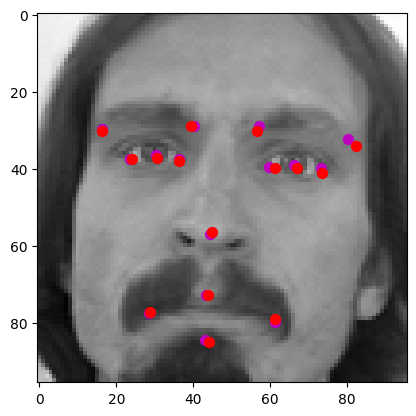

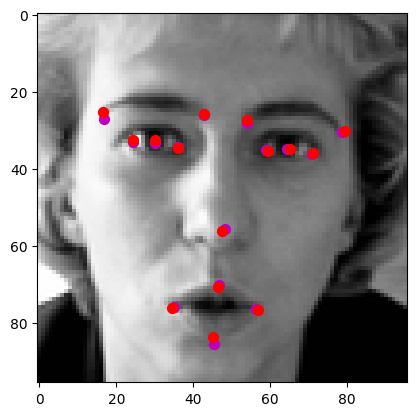

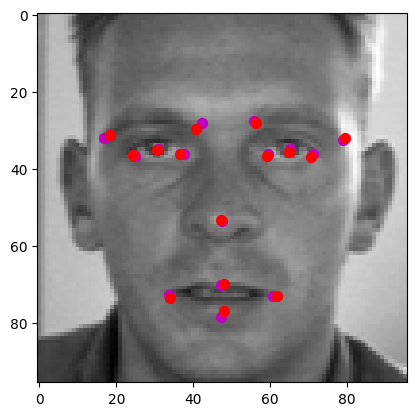

In [52]:
def show_keypoint_predictions(model, loader, num_samples=3):
    model.eval()
    model.to(device)
    batch = next(iter(loader))
    images, keypoints = batch["image"], batch["keypoints"]

    for i in range(num_samples):
        image = images[i].to(device)
        key_pts = keypoints[i].to(device)

        # add batch dimension
        image = image.unsqueeze(0)

        out = model(image).detach()

        predicted_keypoints = torch.squeeze(out).view(15, 2)
        show_all_keypoints(image, key_pts, predicted_keypoints)
        
show_keypoint_predictions(model, val_loader)

In [53]:

print("Score of the Model:", evaluate_model(model, val_dataset))

Score of the Model: 1003.2048687294814


In [54]:
# save the model 
torch.save(model.state_dict(), './model_state_dict.pth')

In [55]:
# load the model
model = FKPModel()
model.load_state_dict(torch.load('./model_state_dict.pth'))

<All keys matched successfully>